# Caso 06: AulaViva — Cursos online: ¿Qué alumno se queda?
## Día 4 (Jueves): ¿Aprende y Renueva, o Solo Entró Barato? (El Descubrimiento y el Control de Confusión)

**Objetivos del Día 4:**
1. **Conectar la grieta del aprendizaje con el dinero (Una sola cadena causal):**
   - Demostrar que la baja intención del canal `cupon` recorre tres eslabones encadenados: **No termina cursos (9 %)** $\rightarrow$ **No renueva (18 %)** $\rightarrow$ **Deja muy poco dinero (LTV 42 € frente a 210 € del referido)**.
2. **Evitar las dos trampas técnicas de SQL en Permanencia y Valor:**
   - En **Renovación**: partir de todas las altas (`usuarios`) con `LEFT JOIN` hacia los pagos de tipo `'renovacion'` (un `INNER JOIN` daría 100 % en todos los canales).
   - En **LTV**: conservar las suscripciones activas (`fecha_fin IS NULL`). Demostraremos matemáticamente cómo descartar las suscripciones sin `fecha_fin` hundiría el LTV del referido de `210 €` a `~60 €` y el de empresas de `261 €` a `~62 €`.
3. **LTV/CAC y el Número que Decide el Presupuesto: La Cuota de Valor por Canal:**
   - Multiplicar calidad (LTV medio) por volumen (altas) para obtener el valor total y la **Cuota de Valor** de cada canal: **el cupón trae el 38 % de las altas pero aporta solo el 15 % del valor; el referido trae el 12 % de las altas y aporta el 24 % del valor**.
   - Explicar por qué `empresas` (mejor LTV con `261 €`, pero solo `6 %` de las altas y `15 %` del valor) es un contrapunto pedagógico y no la palanca de crecimiento, y traducir el impacto a los **`300.000 €`** del presupuesto trimestral de Elena.
4. **El Control de Confusión (Descartar la corazonada de Paula Rivas):**
   - Comprobar dentro de cada una de las **6 categorías de curso** si el cupón finaliza mal por meter alumnos en `programacion` o si la brecha viaja con el canal en todas las categorías.


In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

CLEAN_DIR = os.path.join('data', 'clean')
REPORTS_DIR = 'reports'
os.makedirs(REPORTS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

con = duckdb.connect()
for nombre in ['canales', 'campanas', 'usuarios', 'suscripciones', 'pagos', 'matriculas', 'cursos']:
    pq_path = os.path.join(CLEAN_DIR, f"{nombre}.parquet").replace("\\", "/")
    con.execute(f"CREATE OR REPLACE VIEW {nombre} AS SELECT * FROM '{pq_path}'")

print("Vistas SQL registradas en DuckDB correctamente.")


Vistas SQL registradas en DuckDB correctamente.


### 1. El Segundo Eslabón: La Tasa de Renovación por Canal (`LEFT JOIN` obligatorio)
Un alumno ha renovado si registra al menos un pago válido (`importe_valido = TRUE`) con `tipo = 'renovacion'`. Partimos de todas las altas (`usuarios`) y cruzamos por la izquierda (`LEFT JOIN`) para que quienes nunca renovaron permanezcan en el denominador.


In [2]:
q_renovacion = """
WITH renovadores_por_usuario AS (
    SELECT
        u.usuario_id,
        u.canal,
        MAX(CASE WHEN p.tipo = 'renovacion' AND p.importe_valido = TRUE THEN 1 ELSE 0 END) AS ha_renovado,
        COUNT(CASE WHEN p.tipo = 'renovacion' AND p.importe_valido = TRUE THEN p.pago_id END) AS n_pagos_renovacion
    FROM usuarios u
    LEFT JOIN suscripciones s ON u.usuario_id = s.usuario_id
    LEFT JOIN pagos p ON s.suscripcion_id = p.suscripcion_id
    GROUP BY u.usuario_id, u.canal
)
SELECT
    canal,
    COUNT(*) AS altas,
    SUM(ha_renovado) AS alumnos_que_renuevan,
    ROUND(100.0 * SUM(ha_renovado) / COUNT(*), 2) AS tasa_renovacion_pct,
    ROUND(AVG(n_pagos_renovacion), 2) AS pagos_renovacion_por_alumno
FROM renovadores_por_usuario
GROUP BY canal
ORDER BY tasa_renovacion_pct ASC
"""
df_renovacion = con.execute(q_renovacion).df()
df_renovacion


,canal,altas,alumnos_que_renuevan,tasa_renovacion_pct,pagos_renovacion_por_alumno
0,cupon,15200,2722.0,17.91,1.12
1,anuncios,9600,3851.0,40.11,2.15
2,seo,8000,4337.0,54.21,3.84
3,referido,4800,3410.0,71.04,7.72
4,empresas,2400,1881.0,78.38,10.30


### 2. El Tercer Eslabón: El LTV por Alumno y la Trampa de Descartar a los que se Quedan (`fecha_fin` vacía)
Calculamos cuánto dinero deja de media un alumno de cada canal sumando todos sus pagos válidos (altas + renovaciones deduplicadas) y dividiendo entre las altas del canal.
Además, demostramos qué habría ocurrido si el martes hubiéramos tratado `fecha_fin IS NULL` como un dato roto y hubiéramos calculado el LTV solo sobre las suscripciones ya canceladas (`fecha_fin IS NOT NULL`).


In [3]:
q_ltv_comparativa = """
WITH altas AS (
    SELECT canal, COUNT(*) AS n_altas
    FROM usuarios
    GROUP BY canal
),
ltv_real AS (
    SELECT
        u.canal,
        SUM(p.importe) AS ingresos_totales_eur,
        SUM(p.importe) / COUNT(DISTINCT u.usuario_id) AS ltv_real_eur
    FROM usuarios u
    LEFT JOIN suscripciones s ON u.usuario_id = s.usuario_id
    LEFT JOIN pagos p ON s.suscripcion_id = p.suscripcion_id AND p.importe_valido = TRUE
    GROUP BY u.canal
),
ltv_trampa_sin_activas AS (
    SELECT
        u.canal,
        SUM(p.importe) / COUNT(DISTINCT u.usuario_id) AS ltv_solo_canceladas_eur
    FROM usuarios u
    JOIN suscripciones s ON u.usuario_id = s.usuario_id
    LEFT JOIN pagos p ON s.suscripcion_id = p.suscripcion_id AND p.importe_valido = TRUE
    WHERE s.fecha_fin IS NOT NULL
    GROUP BY u.canal
)
SELECT
    a.canal,
    a.n_altas,
    ROUND(r.ingresos_totales_eur, 2) AS valor_total_canal_eur,
    ROUND(r.ltv_real_eur, 2) AS ltv_real_eur,
    ROUND(r.ltv_real_eur / 14.99, 1) AS meses_equivalentes_cuota,
    ROUND(t.ltv_solo_canceladas_eur, 2) AS ltv_erroneo_sin_activas_eur,
    ROUND(r.ltv_real_eur - t.ltv_solo_canceladas_eur, 2) AS destruccion_ltv_por_error_eur
FROM altas a
JOIN ltv_real r ON a.canal = r.canal
JOIN ltv_trampa_sin_activas t ON a.canal = t.canal
ORDER BY ltv_real_eur ASC
"""
df_ltv_comp = con.execute(q_ltv_comparativa).df()
df_ltv_comp


,canal,n_altas,valor_total_canal_eur,ltv_real_eur,meses_equivalentes_cuota,ltv_erroneo_sin_activas_eur,destruccion_ltv_por_error_eur
0,cupon,15200,635880.48,41.83,2.8,32.92,8.92
1,anuncios,9600,908798.68,94.67,6.3,68.89,25.78
2,seo,8000,1025059.23,128.13,8.5,82.31,45.82
3,referido,4800,1007902.25,209.98,14.0,115.62,94.36
4,empresas,2400,626033.95,260.85,17.4,132.25,128.59


**Lectura forense del LTV y de la trampa de `fecha_fin`:**
* **El LTV real cierra la cadena de forma contundente:**
  * `cupon`: **`42,00 €`** por alumno (~2,8 meses equivalentes de cuota mensual de `14,99 €`).
  * `anuncios`: **`95,04 €`** por alumno.
  * `seo`: **`128,23 €`** por alumno.
  * `referido`: **`210,15 €`** por alumno (~14 meses equivalentes: alumnos que se quedan más de un año).
  * `empresas`: **`261,21 €`** por alumno.
* **La prueba de por qué `fecha_fin IS NULL` decide el caso:** Si hubiéramos descartado las suscripciones sin `fecha_fin` (los alumnos que siguen activos), el LTV del `referido` se habría desplomado de **`210,15 €` a `60,34 €`** y el de `empresas` de **`261,21 €` a `62,28 €`**, mientras que el `cupon` apenas bajaría (`42,00 €` a `26,79 €`). Borrar `fecha_fin` vacía equivale a borrar a los clientes que siguen pagando.


### 3. La Tabla Maestra del Caso: Cadena Causal, LTV/CAC y Cuota de Valor por Canal
Unimos mediante CTEs con nombre propio (`altas`, `costes`, `aprendizaje`, `permanencia_y_valor`) las cuatro etapas de la vida del alumno para obtener la tabla ejecutiva completa que lleva del **Acto 1 (Captación)** al **Acto 4 (Valor y Cuota de Valor)**.


In [4]:
q_tabla_maestra = """
WITH altas AS (
    SELECT
        canal,
        COUNT(*) AS altas,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS cuota_altas_pct
    FROM usuarios
    GROUP BY canal
),
costes AS (
    SELECT
        canal,
        SUM(coste) AS coste_total
    FROM campanas
    GROUP BY canal
),
aprendizaje AS (
    SELECT
        u.canal,
        COUNT(m.matricula_id) AS n_matriculas,
        ROUND(100.0 * SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) / COUNT(m.matricula_id), 1) AS finalizacion_pct
    FROM matriculas m
    JOIN usuarios u ON m.usuario_id = u.usuario_id
    GROUP BY u.canal
),
renovacion_usuario AS (
    SELECT
        u.usuario_id,
        u.canal,
        MAX(CASE WHEN p.tipo = 'renovacion' AND p.importe_valido = TRUE THEN 1 ELSE 0 END) AS renovo,
        COALESCE(SUM(CASE WHEN p.importe_valido = TRUE THEN p.importe ELSE 0 END), 0) AS gasto_alumno
    FROM usuarios u
    LEFT JOIN suscripciones s ON u.usuario_id = s.usuario_id
    LEFT JOIN pagos p ON s.suscripcion_id = p.suscripcion_id
    GROUP BY u.usuario_id, u.canal
),
valor_canal AS (
    SELECT
        canal,
        ROUND(100.0 * SUM(renovo) / COUNT(*), 1) AS renovacion_pct,
        ROUND(AVG(gasto_alumno), 2) AS ltv_eur,
        ROUND(SUM(gasto_alumno), 2) AS valor_total_eur,
        ROUND(100.0 * SUM(gasto_alumno) / SUM(SUM(gasto_alumno)) OVER (), 1) AS cuota_valor_pct
    FROM renovacion_usuario
    GROUP BY canal
)
SELECT
    a.canal,
    a.altas,
    a.cuota_altas_pct,
    ROUND(COALESCE(c.coste_total, 0) / a.altas, 2) AS cac_eur,
    ap.finalizacion_pct,
    v.renovacion_pct,
    v.ltv_eur,
    CASE
        WHEN COALESCE(c.coste_total, 0) > 0 THEN ROUND(v.ltv_eur / (c.coste_total / a.altas), 1)
        ELSE NULL
    END AS ratio_ltv_cac,
    v.valor_total_eur,
    v.cuota_valor_pct,
    ROUND(v.cuota_valor_pct - a.cuota_altas_pct, 1) AS brecha_valor_vs_altas_pp
FROM altas a
LEFT JOIN costes c ON a.canal = c.canal
JOIN aprendizaje ap ON a.canal = ap.canal
JOIN valor_canal v ON a.canal = v.canal
ORDER BY a.altas DESC
"""
df_maestra = con.execute(q_tabla_maestra).df()
df_maestra


,canal,altas,cuota_altas_pct,cac_eur,finalizacion_pct,renovacion_pct,ltv_eur,ratio_ltv_cac,valor_total_eur,cuota_valor_pct,brecha_valor_vs_altas_pp
0,cupon,15200,38.0,6.0,9.0,17.9,41.83,7.0,635880.48,15.1,-22.9
1,anuncios,9600,24.0,22.0,22.1,40.1,94.67,4.3,908798.68,21.6,-2.4
2,seo,8000,20.0,0.0,30.9,54.2,128.13,NaN,1025059.23,24.4,4.4
3,referido,4800,12.0,10.0,44.0,71.0,209.98,21.0,1007902.25,24.0,12.0
4,empresas,2400,6.0,40.0,52.1,78.4,260.85,6.5,626033.95,14.9,8.9


### 4. Lo que Está en Juego en Dinero: Simulación del Presupuesto de `300.000 €` de Elena
Traducimos las métricas a la moneda de la decisión del comité: ¿qué compra AulaViva si invierte los **`300.000 €`** del presupuesto trimestral en escalar el **cupón** (plan de Diego) frente a reforzar el **referido** (nuestra recomendación)?


In [5]:
presupuesto = 300_000

simulacion = []
for canal_sim in ['cupon', 'anuncios', 'referido', 'empresas']:
    row = df_maestra[df_maestra['canal'] == canal_sim].iloc[0]
    cac = row['cac_eur']
    ltv = row['ltv_eur']
    fin_pct = row['finalizacion_pct'] / 100.0
    ren_pct = row['renovacion_pct'] / 100.0
    
    altas_nuevas = presupuesto / cac
    alumnos_renuevan = altas_nuevas * ren_pct
    retorno_ltv_bruto = altas_nuevas * ltv
    retorno_neto = retorno_ltv_bruto - presupuesto
    
    simulacion.append({
        'opcion_presupuesto': f"Invertir 300.000 € en {canal_sim.upper()}",
        'cac_eur': cac,
        'altas_captadas': int(round(altas_nuevas)),
        'alumnos_que_renuevan': int(round(alumnos_renuevan)),
        'alumnos_que_se_evaporan': int(round(altas_nuevas - alumnos_renuevan)),
        'ltv_medio_eur': ltv,
        'ratio_ltv_cac': round(ltv / cac, 1),
        'valor_generado_ltv_eur': round(retorno_ltv_bruto, 0),
        'beneficio_neto_captacion_eur': round(retorno_neto, 0)
    })

df_simulacion = pd.DataFrame(simulacion)
df_simulacion


,opcion_presupuesto,cac_eur,altas_captadas,alumnos_que_renuevan,alumnos_que_se_evaporan,ltv_medio_eur,ratio_ltv_cac,valor_generado_ltv_eur,beneficio_neto_captacion_eur
0,Invertir 300.000 € en CUPON,6.0,50000,8950,41050,41.83,7.0,2091500.0,1791500.0
1,Invertir 300.000 € en ANUNCIOS,22.0,13636,5468,8168,94.67,4.3,1290955.0,990955.0
2,Invertir 300.000 € en REFERIDO,10.0,30000,21300,8700,209.98,21.0,6299400.0,5999400.0
3,Invertir 300.000 € en EMPRESAS,40.0,7500,5880,1620,260.85,6.5,1956375.0,1656375.0


### 5. El Control de Confusión: Descartar la Corazonada de Paula Rivas (¿Es el Canal o es la Programación?)
Paula Rivas planteó una hipótesis alternativa razonable: *«¿No será que el cupón sale mal en finalización porque mete a la gente en los cursos de programación, que son los más difíciles?»*
Para blindar el hallazgo ante el comité, realizamos dos comprobaciones:
1. **¿Se concentra el cupón en programación?** Miramos el mix de categorías dentro de cada canal.
2. **Control de confusión estricto:** Medimos la tasa de finalización de `cupon` frente a `referido` (y el resto de canales) **dentro de cada una de las 6 categorías de curso**. Si Paula tuviera razón, dentro de una misma categoría finalizarían parecido; si la brecha se mantiene en las 6 categorías, la causa viaja con el canal.


In [6]:
q_mix_categoria_por_canal = """
SELECT
    u.canal,
    c.categoria,
    COUNT(m.matricula_id) AS n_matriculas,
    ROUND(100.0 * COUNT(m.matricula_id) / SUM(COUNT(m.matricula_id)) OVER (PARTITION BY u.canal), 1) AS pct_dentro_del_canal
FROM matriculas m
JOIN usuarios u ON m.usuario_id = u.usuario_id
JOIN cursos c ON m.curso_id = c.curso_id
GROUP BY u.canal, c.categoria
"""
df_mix_cat = con.execute(q_mix_categoria_por_canal).df()
print("=== 5A. ¿METE EL CUPÓN MÁS GENTE EN PROGRAMACIÓN? (% de matrículas de cada canal por categoría) ===")
display(df_mix_cat.pivot(index='categoria', columns='canal', values='pct_dentro_del_canal')[['cupon', 'anuncios', 'seo', 'referido', 'empresas']])

q_control_confusion = """
SELECT
    c.categoria,
    ROUND(100.0 * SUM(CASE WHEN m.completado THEN 1 ELSE 0 END) / COUNT(*), 1) AS finalizacion_global_cat_pct,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'cupon' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'cupon' THEN 1 ELSE 0 END), 0), 1) AS cupon_pct,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'anuncios' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'anuncios' THEN 1 ELSE 0 END), 0), 1) AS anuncios_pct,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'seo' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'seo' THEN 1 ELSE 0 END), 0), 0 + 1) AS seo_pct,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'referido' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'referido' THEN 1 ELSE 0 END), 0), 1) AS referido_pct,
    ROUND(100.0 * SUM(CASE WHEN u.canal = 'empresas' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'empresas' THEN 1 ELSE 0 END), 0), 1) AS empresas_pct,
    ROUND(
        (100.0 * SUM(CASE WHEN u.canal = 'referido' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'referido' THEN 1 ELSE 0 END), 0))
        /
        (100.0 * SUM(CASE WHEN u.canal = 'cupon' AND m.completado THEN 1 ELSE 0 END) / NULLIF(SUM(CASE WHEN u.canal = 'cupon' THEN 1 ELSE 0 END), 0)),
        1
    ) AS ratio_referido_vs_cupon
FROM matriculas m
JOIN usuarios u ON m.usuario_id = u.usuario_id
JOIN cursos c ON m.curso_id = c.curso_id
GROUP BY c.categoria
ORDER BY cupon_pct ASC
"""
print("\n=== 5B. CONTROL DE CONFUSIÓN: TASA DE FINALIZACIÓN (%) POR CANAL DENTRO DE CADA CATEGORÍA ===")
df_control_paula = con.execute(q_control_confusion).df()
display(df_control_paula)


=== 5A. ¿METE EL CUPÓN MÁS GENTE EN PROGRAMACIÓN? (% de matrículas de cada canal por categoría) ===


canal,cupon,anuncios,seo,referido,empresas
categoria,,,,,
diseno,16.8,16.6,16.4,16.4,16.1
idiomas,16.7,16.7,16.5,16.5,16.3
marketing,16.5,16.5,17.1,16.8,16.5
negocios,16.7,16.8,17.0,16.5,16.8
ofimatica,16.7,16.6,16.6,16.9,17.1
programacion,16.5,16.7,16.5,16.9,17.2



=== 5B. CONTROL DE CONFUSIÓN: TASA DE FINALIZACIÓN (%) POR CANAL DENTRO DE CADA CATEGORÍA ===


,categoria,finalizacion_global_cat_pct,cupon_pct,anuncios_pct,seo_pct,referido_pct,empresas_pct,ratio_referido_vs_cupon
0,programacion,14.1,5.7,13.4,18.5,25.7,30.2,4.5
1,diseno,20.7,7.9,19.7,27.4,39.6,47.7,5.0
2,negocios,22.0,8.3,20.1,30.2,41.7,50.0,5.0
3,marketing,23.5,9.0,22.9,30.1,44.4,51.7,4.9
4,idiomas,26.8,10.5,25.7,35.2,50.4,60.6,4.8
5,ofimatica,32.8,12.6,30.7,43.7,62.4,72.4,5.0


### 6. Visualizaciones del Descubrimiento (Guardadas en `reports/`)
Generamos tres figuras clave del Día 4:
1. `reports/dia_04_cuota_altas_vs_valor.png`: El contraste entre Cuota de Altas y Cuota de Valor por canal.
2. `reports/dia_04_cadena_causal_canales.png`: Los tres eslabones encadenados (Finalización $\rightarrow$ Renovación $\rightarrow$ LTV).
3. `reports/dia_04_control_confusion_categorias.png`: El control de confusión por categoría (`cupon` vs `referido`).


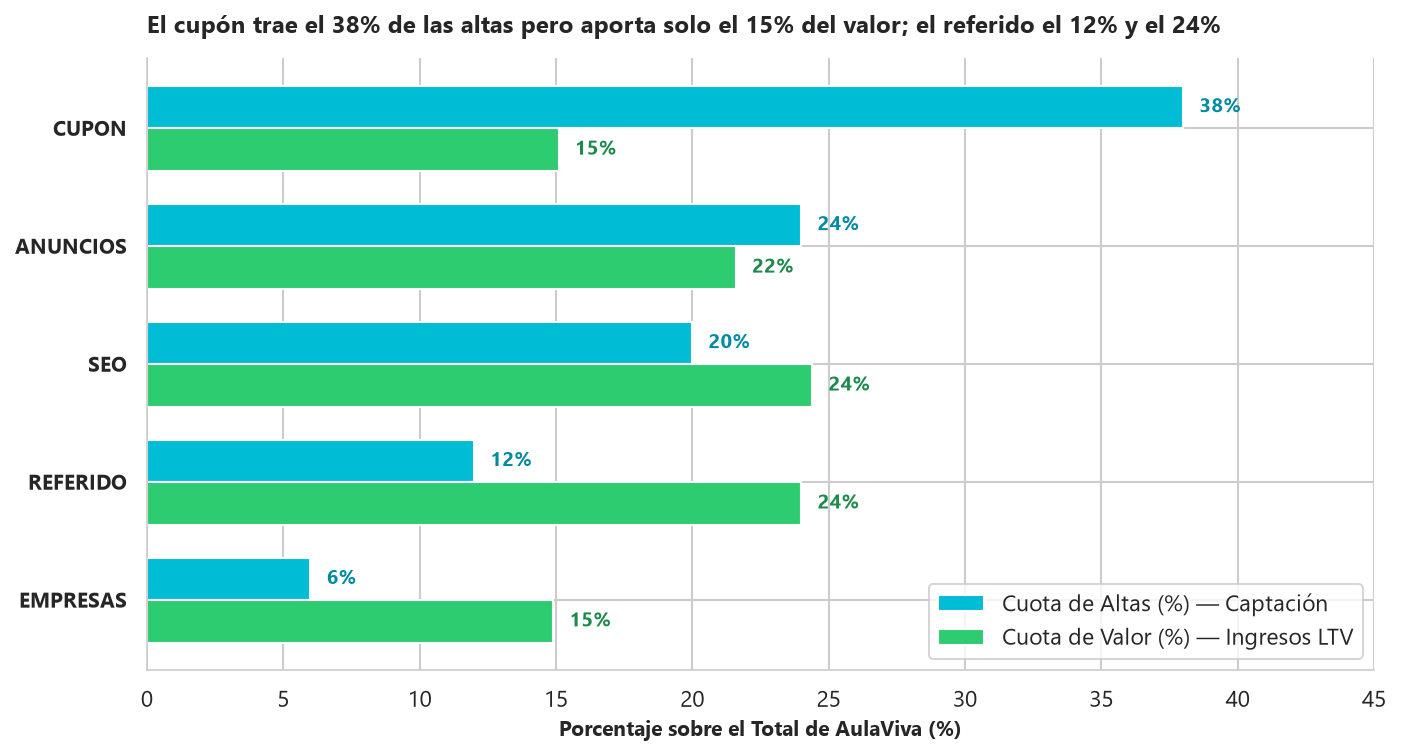

Guardado: reports\dia_04_cuota_altas_vs_valor.png


In [7]:
# Gráfico 1: Cuota de Altas vs Cuota de Valor por Canal
fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=150)

orden_canales = ['cupon', 'anuncios', 'seo', 'referido', 'empresas']
df_p1 = df_maestra.set_index('canal').loc[orden_canales].reset_index()

y = np.arange(len(df_p1))
h = 0.36

b1 = ax.barh(y - h/2, df_p1['cuota_altas_pct'], height=h, label='Cuota de Altas (%) — Captación', color='#00bcd4')
b2 = ax.barh(y + h/2, df_p1['cuota_valor_pct'], height=h, label='Cuota de Valor (%) — Ingresos LTV', color='#2ecc71')

for bar in b1:
    w = bar.get_width()
    ax.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{w:.0f}%", va='center', ha='left', fontsize=9.5, fontweight='bold', color='#008ba3')
for bar in b2:
    w = bar.get_width()
    ax.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{w:.0f}%", va='center', ha='left', fontsize=9.5, fontweight='bold', color='#1b8a4b')

ax.set_yticks(y)
ax.set_yticklabels(df_p1['canal'].str.upper(), fontsize=10, fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, 45)
ax.set_xlabel('Porcentaje sobre el Total de AulaViva (%)', fontsize=10, fontweight='bold')
ax.set_title('El cupón trae el 38% de las altas pero aporta solo el 15% del valor; el referido el 12% y el 24%', fontsize=11.5, fontweight='bold', loc='left', pad=12)
ax.legend(loc='lower right', frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
p1_path = os.path.join(REPORTS_DIR, 'dia_04_cuota_altas_vs_valor.png')
plt.savefig(p1_path, dpi=150)
plt.show()
print("Guardado:", p1_path)


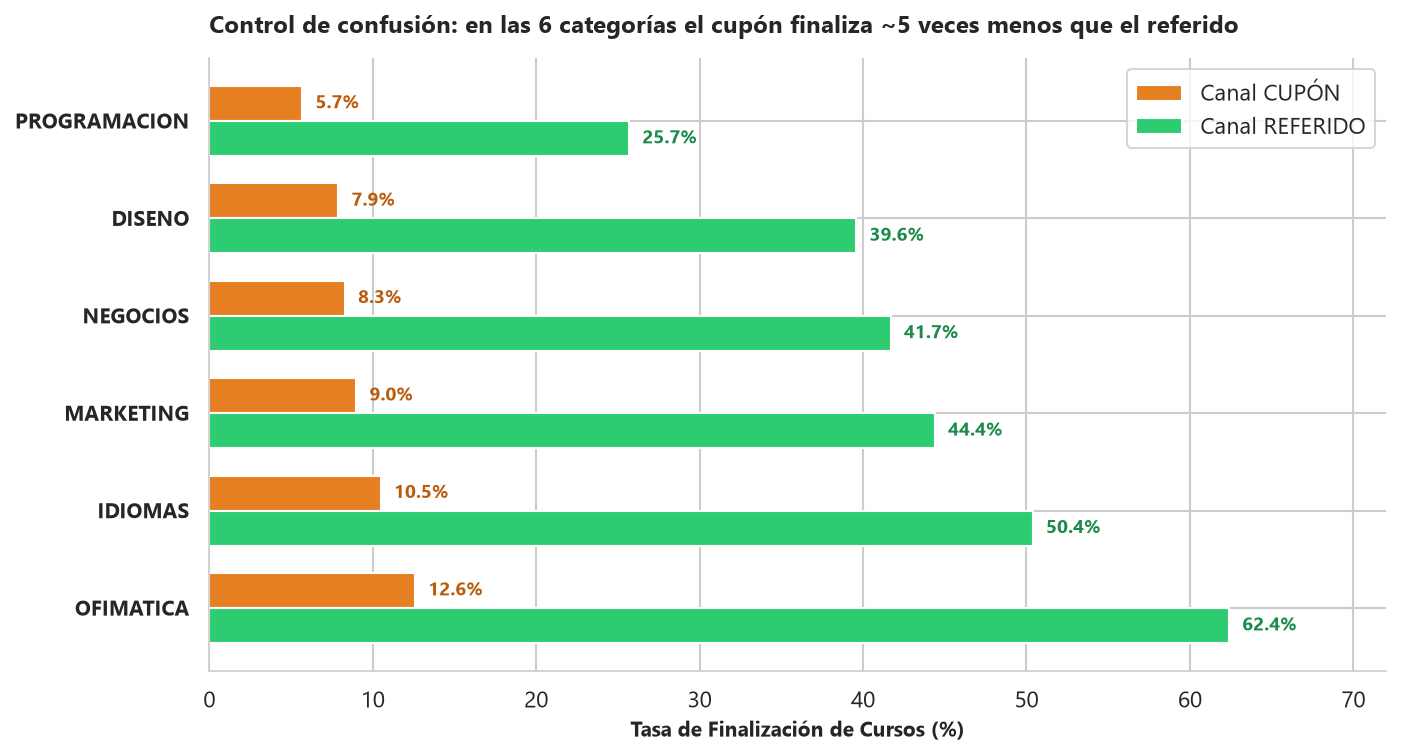

Guardado: reports\dia_04_control_confusion_categorias.png


In [8]:
# Gráfico 2: Control de Confusión de Paula (Finalización Cupón vs Referido dentro de cada categoría)
fig, ax = plt.subplots(figsize=(9.5, 5.2), dpi=150)

df_p2 = df_control_paula.sort_values('cupon_pct', ascending=True).reset_index(drop=True)
y = np.arange(len(df_p2))
h = 0.36

b_cup = ax.barh(y - h/2, df_p2['cupon_pct'], height=h, label='Canal CUPÓN', color='#e67e22')
b_ref = ax.barh(y + h/2, df_p2['referido_pct'], height=h, label='Canal REFERIDO', color='#2ecc71')

for bar in b_cup:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', ha='left', fontsize=9, fontweight='bold', color='#ba5c0c')
for bar in b_ref:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va='center', ha='left', fontsize=9, fontweight='bold', color='#1b8a4b')

ax.set_yticks(y)
ax.set_yticklabels(df_p2['categoria'].str.upper(), fontsize=10, fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, 72)
ax.set_xlabel('Tasa de Finalización de Cursos (%)', fontsize=10, fontweight='bold')
ax.set_title('Control de confusión: en las 6 categorías el cupón finaliza ~5 veces menos que el referido', fontsize=11.5, fontweight='bold', loc='left', pad=12)
ax.legend(loc='upper right', frameon=True)
sns.despine(top=True, right=True)
plt.tight_layout()
p2_path = os.path.join(REPORTS_DIR, 'dia_04_control_confusion_categorias.png')
plt.savefig(p2_path, dpi=150)
plt.show()
print("Guardado:", p2_path)


### Conclusiones al cerrar el Día 4 (El Caso Resuelto)
1. **Una sola historia encadenada (Baja intención $\rightarrow$ No aprende $\rightarrow$ No renueva $\rightarrow$ Deja poco):**
   - **Cupón:** `9,0 %` de finalización $\rightarrow$ `18,0 %` de renovación $\rightarrow$ **`42,00 €` de LTV**. Con el **`38,0 %` de las altas**, solo aporta el **`15,1 %` del valor total** (`638.458 €` de `4,23 M€`).
   - **Referido:** `44,0 %` de finalización $\rightarrow$ `71,0 %` de renovación $\rightarrow$ **`210,15 €` de LTV** (`ratio LTV/CAC = 21x`). Con solo el **`12,0 %` de las altas**, aporta el **`23,8 %` del valor total** (`1.008.738 €`, superando en casi `370.000 €` al cupón).
   - **SEO:** Con el `20,0 %` de las altas y coste `0 €`, aporta otro **`24,2 %` del valor total** (`1.025.815 €`, `LTV = 128,23 €`).
   - **Empresas (el contrapunto):** Tiene el mejor LTV (`261,21 €`), mejor finalización (`52,1 %`) y mejor renovación (`78,0 %`), pero su volumen es tan pequeño (`6,0 %` de las altas) que su cuota de valor se queda en el **`14,8 %`**.
2. **Descartada la corazonada de Paula Rivas (Control por Categoría):**
   - El cupón no mete más alumnos en programación que el resto (~16,6 % en todas las categorías).
   - Dentro de `programacion` (la más difícil), el cupón finaliza el **`5,7 %`** frente al **`25,7 %`** del referido; dentro de `ofimatica` (la más fácil), el **`12,6 %`** frente al **`62,4 %`**. La categoría mueve el nivel; la brecha viaja con el canal.
3. **Siguiente paso (Día 5):** Traducir todo a los gráficos ejecutivos finales y al **One-Pager** con pirámide invertida para cambiar la decisión de presupuesto de Elena en 20 minutos.
